# Médias móveis como régua — Etapa 2 do plano de previsão

**Objetivo:** medir quanto regras simples acertam o **total vendido nos 3 meses seguintes** de cada produto × loja, onde erram e qual o viés delas. A melhor régua vira a nota mínima que um modelo de machine learning precisa superar.

**Resposta curta:** a previsão de cada produto × loja para os próximos 3 meses é **média da categoria no local × índice sazonal × tendência**. Somando os produtos, essa régua erra bem menos por categoria e por local do que olhar só para o histórico do próprio produto, e quase não tem viés. O achado central: **o histórico de um produto não informa quanto ele vai vender**; o que prevê é o nível do grupo, a sazonalidade e a tendência.

**De onde vem o desenho** (notebooks 01 e 02):

| O que já sabemos | Como entra aqui |
|---|---|
| Série mensal, alvo = total dos 3 meses seguintes | Cada linha é uma série × mês de corte, e o alvo soma os 3 meses depois do corte |
| Nenhuma série nova, e a maioria das "paradas" volta a vender | Todas as séries entram, sem regras separadas |
| Mesma sazonalidade em todas as categorias | Um índice sazonal geral |
| Demanda crescendo ano a ano | Medir o viés das médias e testar uma correção de tendência |
| Séries muito parecidas entre si; quase todo produto vende nos 6 locais | Testar se o nível vem da própria série, do produto nos 6 locais ou da categoria no local |

**Termos:**

| Termo | O que quer dizer, em palavras simples |
|---|---|
| Corte | O "hoje" do teste: o mês em que fingimos estar fazendo a previsão. Só pode usar o que já tinha acontecido até esse mês, nunca o futuro |
| Alvo | Quanto realmente foi vendido nos 3 meses seguintes ao corte — o número que a previsão está tentando acertar |
| MM12 / MM3 | A venda média por mês, olhando para os últimos 12 meses (MM12) ou só os últimos 3 (MM3) |
| Índice sazonal | Um número que diz se um mês vende mais ou menos que a média do ano. 1,5 = esse mês vende 50% a mais que a média |
| Fator de tendência | Um número um pouco maior que 1 que "empurra" a previsão para cima, para compensar o fato de a demanda estar crescendo com o tempo |
| Erro (WAPE) | De cada 100 unidades vendidas, quantas a previsão errou para mais ou para menos. Prever sempre "zero" já dá 100% de erro |
| MAE | O erro médio, **em unidades**, de cada previsão por produto × loja. MAE 5 = a previsão erra, em média, 5 unidades por produto em 3 meses |
| RMSE | Parecido com o MAE, mas os erros grandes pesam bem mais. Se o RMSE é muito maior que o MAE, poucos produtos têm erros enormes |
| Viés | Diz se a previsão costuma ficar para cima ou para baixo da venda real, em média. Viés de −10% = a previsão, no total, fica 10% abaixo do que de fato foi vendido |
| Limite de venda (`q_75`, `q_90`) | Um teto: "a venda não deve passar disso". `q_75` = teto que segura a venda real em 3 de cada 4 vezes; `q_90` = teto que segura em 9 de cada 10 vezes |

Os cálculos ficam em `src/analytics_ai/demand_moving_average.py`.

## Resumo em palavras simples (sem estatística)

Imagine que você quer saber quantos motores de popa uma loja vai vender nos próximos 3 meses. Dá pra pensar assim, passo a passo:

1. **Não olhe só para aquele motor específico.** Um produto sozinho vende pouco e de forma irregular — um mês vende 3, no outro vende 0, no outro vende 8. Esse vaivém é sorte, não é um padrão que se repete (a seção 8 mostra isso: quem vendeu mais no ano passado não é quem vai vender mais este ano). Então, em vez de usar o histórico *daquele* motor, usamos a média de venda de **todos os motores daquela loja**. Um grupo maior de produtos "balança" muito menos que um produto isolado, então essa média é uma base bem mais confiável.
2. **Ajuste pela época do ano.** Se estamos prevendo dezembro a fevereiro (verão, alta temporada de barcos), a previsão precisa ser maior do que se estivéssemos prevendo junho a agosto. Esse ajuste é o "índice sazonal".
3. **Ajuste pelo crescimento.** As vendas da loja estão crescendo ano a ano. Se você só olhar a média do que já vendeu, vai sempre chutar um pouco abaixo do que realmente vai vender, porque o passado é sempre "menor" que o presente numa empresa que está crescendo. Por isso multiplicamos por um fatorzinho de tendência para compensar.

Juntando os três passos (média do grupo × ajuste de época × ajuste de crescimento) chegamos num número esperado de venda.

**Só o número esperado não basta**, porque a venda de um produto varia muito ao redor dele. Por isso a previsão também entrega dois "tetos": um teto que a venda real ultrapassa só 1 em cada 4 vezes, e um teto mais alto que ela ultrapassa só 1 em cada 10 vezes — como uma previsão do tempo ("deve ficar perto de 25°C, mas pode chegar a 30°C algumas vezes"). Testamos esses tetos em dados que a régua nunca tinha visto, e eles se confirmaram (seção 12).

**Sobre o erro:** para um produto isolado numa loja, a previsão erra bastante (a venda de um item é quase um jogo de sorte). Mas quando juntamos vários produtos — por exemplo, tudo o que uma loja vende — os erros de cada produto se cancelam entre si, e o erro total fica bem menor (seção 9). Isso é ótimo para quem decide compra de estoque por categoria ou planeja por loja.

**A descoberta mais importante do notebook:** olhar para o histórico de um produto específico não ajuda a prever o futuro dele. Um produto que vendeu muito mais que outro no ano passado não tem mais chance de continuar vendendo mais — é como jogar uma moeda: quem tirou cara 3 vezes seguidas não tem mais chance de tirar cara na próxima. O que realmente prevê a venda é o grupo (categoria + loja), a época do ano e a tendência de crescimento — não o histórico individual do produto.

A seção 14, no fim do notebook, junta esses números numa "prova" que qualquer modelo de machine learning mais sofisticado, feito depois, vai precisar superar para valer a pena ser usado.

## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

from src.analytics_ai.demand_common import (
    add_months,
    aggregated_error_table,
    comparison_scorecard,
    cutoff_months,
    error_table,
)
from src.analytics_ai.demand_moving_average import (
    add_forecasts,
    apply_interval_buckets,
    build_cutoff_panel,
    fit_interval_buckets,
    interval_coverage,
    monthly_totals,
    past_volume_quintiles,
    trend_factor_at,
)
from src.analytics_ai.eda_common import add_frequency_class, complete_months, reference_month
from src.analytics_ai.ml_config import MlFeatureConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C"]

config = MlFeatureConfig.from_environment_monthly()
DATE_COL = config.date_col

complete = complete_months(spark.table(config.source_table), DATE_COL)
products = spark.table(config.gold_table("dim_products")).select("sk_product", "sku", "product_name", "category_name")
locations = spark.table(config.gold_table("dim_locations")).select("sk_location", "location_name")

LAST_MONTH = reference_month(complete, DATE_COL)
# Teste: os 12 últimos cortes cujo alvo de 3 meses já aconteceu.
CUTOFFS = cutoff_months(LAST_MONTH, n_cutoffs=12)
# Calibração da faixa (seção 11): 24 cortes cujo alvo termina antes do primeiro corte de teste.
CALIBRATION_CUTOFFS = cutoff_months(CUTOFFS[0], n_cutoffs=24)

print(f"último mês completo: {LAST_MONTH}")
print(f"cortes de teste: {CUTOFFS[0]} a {CUTOFFS[-1]} ({len(CUTOFFS)} cortes)")

último mês completo: 2026-08-01
cortes de teste: 2025-06-01 a 2026-05-01 (12 cortes)


## 1. O painel de teste

Uma linha por série × mês de corte, com as somas dos últimos 12 e 3 meses e o alvo (total dos 3 meses seguintes). A frequência de venda (alta, média, baixa) é calculada **no corte**, com as mesmas faixas do notebook 02.

,cutoff,vendido,zero_rate
0,2025-06-01,17563.0,0.584242
1,2025-07-01,24561.0,0.475223
2,2025-08-01,33590.0,0.363892
3,2025-09-01,42042.0,0.283944
4,2025-10-01,50336.0,0.217872
5,2025-11-01,51261.0,0.220846
6,2025-12-01,52850.0,0.209779
7,2026-01-01,45038.0,0.264453
8,2026-02-01,37868.0,0.324744
9,2026-03-01,26356.0,0.453419


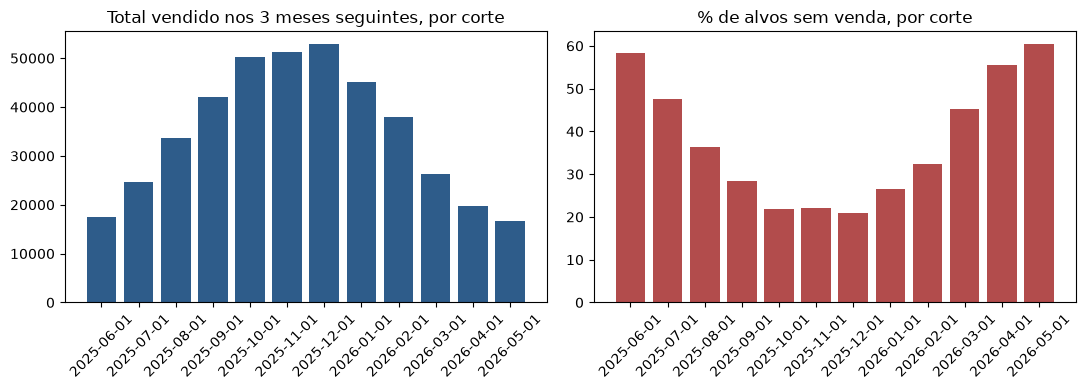

In [3]:
# Painel: uma linha por série × corte, com as somas de 12 e 3 meses e o alvo.
panel_all = (
    add_frequency_class(build_cutoff_panel(complete, CALIBRATION_CUTOFFS + CUTOFFS, DATE_COL))
    .join(products, "sk_product")
    .join(locations, "sk_location")
    .toPandas()
)
# Demanda total por mês, base do índice sazonal e da tendência.
totals = monthly_totals(complete, DATE_COL)

# As seções 1 a 10 usam só os cortes de teste; os de calibração entram na seção 11.
panel = panel_all[panel_all["cutoff"].isin(CUTOFFS)]

# Total vendido e % de zeros do alvo, por corte.
by_cutoff_panel = panel.groupby("cutoff").agg(
    vendido=("target_3m", "sum"),
    zero_rate=("target_3m", lambda s: (s == 0).mean()),
).reset_index()
display(by_cutoff_panel)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(by_cutoff_panel["cutoff"].astype(str), by_cutoff_panel["vendido"], color=CORES[0])
axes[0].set_title("Total vendido nos 3 meses seguintes, por corte")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(by_cutoff_panel["cutoff"].astype(str), by_cutoff_panel["zero_rate"] * 100, color=CORES[3])
axes[1].set_title("% de alvos sem venda, por corte")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**O que o gráfico mostra:** o alvo muda muito com a época — cortes que preveem a alta temporada vendem bem mais e têm menos zeros; cortes que preveem a baixa vendem menos e têm mais zeros. **O índice sazonal é indispensável.**

## 2. Tendência em cada corte

Recalculada com os meses até cada corte, como aconteceria na prática: crescimento dos 12 meses até o corte contra os 12 anteriores, e o **fator de tendência** que empurra a previsão para compensar esse crescimento.

**Fórmula:**

$$
\text{growth}_{12m}(c) = \frac{\sum_{t \in (c-12,\,c]} D_t}{\sum_{t \in (c-24,\,c-12]} D_t}
$$

$$
\text{trend\_factor}(c) = \text{growth}_{12m}(c)^{\,7.5/12}
$$

- $D_t$ = demanda total (todas as séries somadas) no mês $t$
- $c$ = mês de corte
- o expoente $7{,}5/12$ é a distância, em meses, entre o centro da janela de 12 meses (5,5 meses antes do corte) e o centro dos 3 meses previstos (2 meses depois do corte) — ajusta a força da correção a essa distância, em vez de aplicar o crescimento do ano inteiro de uma só vez

,corte,crescimento_12m,fator_tendencia
0,2025-06-01,1.129,1.079
1,2025-07-01,1.132,1.080
2,2025-08-01,1.145,1.088
3,2025-09-01,1.162,1.098
4,2025-10-01,1.170,1.103
5,2025-11-01,1.180,1.109
6,2025-12-01,1.170,1.103
7,2026-01-01,1.180,1.109
8,2026-02-01,1.188,1.114
9,2026-03-01,1.172,1.104


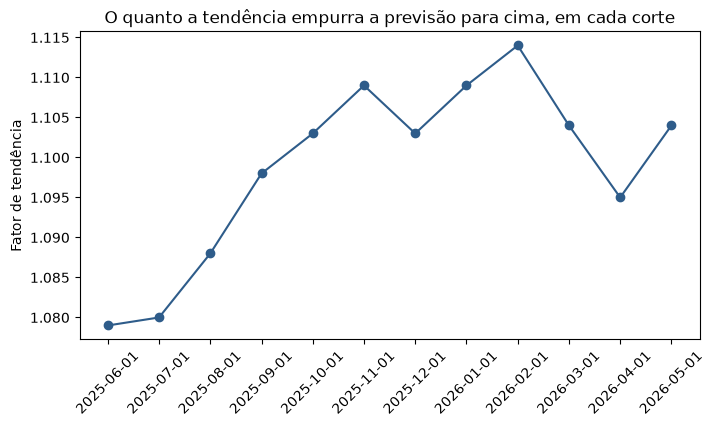

In [4]:
# Crescimento e fator de tendência recalculados em cada corte.
trend_by_cutoff = pd.DataFrame(
    [{"corte": c, "crescimento_12m": g, "fator_tendencia": f} for c in CUTOFFS for g, f in [trend_factor_at(totals, c)]]
).round(3)
display(trend_by_cutoff)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(trend_by_cutoff["corte"].astype(str), trend_by_cutoff["fator_tendencia"], marker="o", color=CORES[0])
ax.set_ylabel("Fator de tendência")
ax.set_title("O quanto a tendência empurra a previsão para cima, em cada corte")
plt.xticks(rotation=45)
plt.show()

**O que o gráfico mostra:** o fator de tendência fica sempre acima de 1 e é bem estável entre os cortes. A tendência é forte e constante: as médias do passado, sozinhas, vão prever sistematicamente abaixo do real.

## 3. As três réguas

| Régua | Previsão do total dos 3 meses | Pergunta |
|---|---|---|
| MM12 | média mensal dos últimos 12 meses × 3 | O nível médio do ano basta? |
| MM12 × índice | média dos últimos 12 meses × soma dos índices dos 3 meses previstos | Ajustar pela sazonalidade melhora? |
| MM3 | média dos últimos 3 meses × 3 | O passado recente importa mais que o ano? |

**Fórmula do erro (WAPE):**

$$
\text{WAPE} = \frac{\sum_i |\hat y_i - y_i|}{\sum_i y_i}
$$

**Fórmula do viés:**

$$
\text{viés} = \frac{\sum_i \hat y_i - \sum_i y_i}{\sum_i y_i}
$$

- $y_i$ = `target_3m` real da série $i$ (venda real nos 3 meses seguintes ao corte)
- $\hat y_i$ = previsão da régua para a série $i$
- viés positivo → a régua prevê mais do que o real; negativo → prevê menos

,regua,n,wape,vies,erro_relativo
0,MM12,72648,0.9923,-0.0808,1.0000
1,MM12 × índice,72648,0.9310,-0.1168,0.9382
2,MM3,72648,1.2047,-0.0193,1.2140


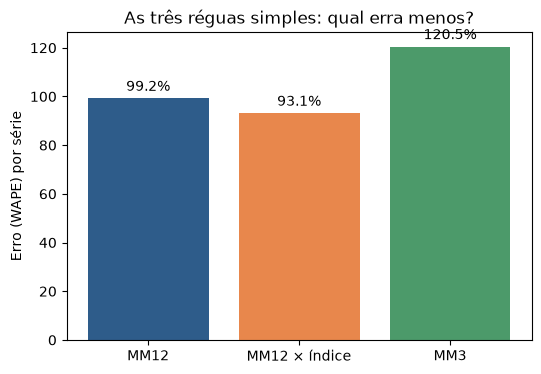

In [5]:
# Grupos usados para o nível: produto nos 6 locais e categoria no local.
GROUPS = {"produto": ["sk_product"], "categoria_loja": ["category_name", "sk_location"]}
# Acrescenta a previsão de cada régua a todas as linhas do painel.
forecasts_all = add_forecasts(panel_all, totals, GROUPS)
# Avaliação só nos cortes de teste.
forecasts = forecasts_all[forecasts_all["cutoff"].isin(CUTOFFS)].copy()

# Nome no gráfico → coluna de previsão.
REGUAS = {"MM12": "pred_mm12", "MM12 × índice": "pred_mm12_idx", "MM3": "pred_mm3"}
base_error = error_table(forecasts, REGUAS)
display(base_error)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(base_error["regua"], base_error["wape"] * 100, color=CORES[:3])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("Erro (WAPE) por série")
ax.set_title("As três réguas simples: qual erra menos?")
plt.show()

**O que o gráfico mostra:** ajustar pela sazonalidade já ajuda. A MM3 é a pior das três — numa série que vende em poucos meses do ano, a média de 3 meses oscila entre zero e picos. Por série, o erro de todas fica alto (perto do que se erraria prevendo sempre zero): não é defeito das réguas, é o ruído natural de uma série individual (notebook 01). O erro por série sozinho não serve para comparar réguas; as seções 9 e 10 medem na soma, que é como a previsão é usada de verdade.

## 4. Quem vendeu muito no passado é "superprevisto"

A frequência de venda no corte (quantos dos últimos 12 meses a série vendeu) é a divisão que mais diferencia as séries. O gráfico mostra o **viés** da MM12 × índice em cada frequência: positivo significa que a régua prevê mais do que a série realmente vende depois.

,frequency_class,regua,n,wape,vies
1,baixa,MM12 × índice,22505,0.8892,-0.5318
2,media,MM12 × índice,34954,0.8974,-0.0460
0,alta,MM12 × índice,13571,1.0788,0.5051


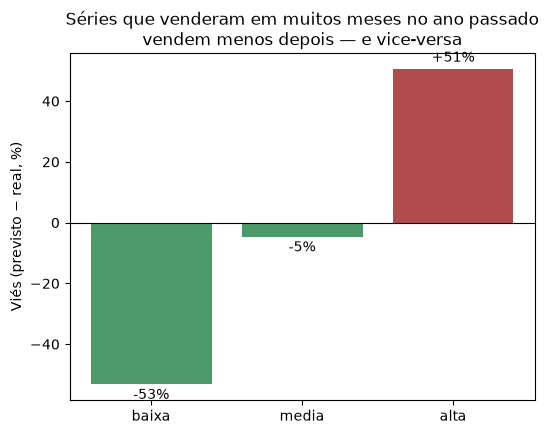

In [6]:
# Viés da MM12 × índice em cada classe de frequência do corte.
by_frequency_bias = error_table(forecasts, {"MM12 × índice": "pred_mm12_idx"}, by=["frequency_class"])
order = ["baixa", "media", "alta"]
by_frequency_bias = by_frequency_bias[by_frequency_bias["frequency_class"].isin(order)].copy()
by_frequency_bias["frequency_class"] = pd.Categorical(by_frequency_bias["frequency_class"], categories=order, ordered=True)
by_frequency_bias = by_frequency_bias.sort_values("frequency_class")
display(by_frequency_bias)

fig, ax = plt.subplots(figsize=(6, 4.5))
# Vermelho: a régua prevê a mais; verde: prevê a menos.
colors = [CORES[3] if v > 0 else CORES[2] for v in by_frequency_bias["vies"]]
bars = ax.bar(by_frequency_bias["frequency_class"], by_frequency_bias["vies"] * 100, color=colors)
ax.bar_label(bars, fmt="%+.0f%%", padding=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Viés (previsto − real, %)")
ax.set_title("Séries que venderam em muitos meses no ano passado\nvendem menos depois — e vice-versa")
plt.show()

**O que o gráfico mostra:** as séries que venderam em muitos meses no último ano vendem **menos** depois (viés positivo: a régua prevê a mais), e as que venderam pouco vendem **mais** (viés negativo). É o mesmo efeito de um jogador de basquete que acerta 9 em 10 arremessos numa partida — na próxima, ele tende a voltar ao seu normal, não a manter os 90%. A frequência medida no passado descreve a sorte do último ano, não a série. Confiar demais no quanto um produto vendeu recentemente engana a previsão.

## 5. Erro por mês de corte

O erro muda conforme a época do ano prevista?

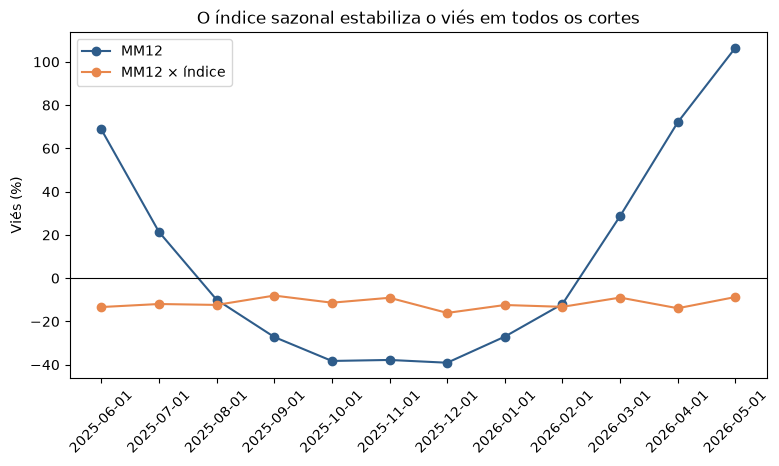

Erro por categoria: entre 91.4% e 94.9% — todas parecidas.


regua,MM12,MM12 × índice
cutoff,,
2025-06-01,68.8,-13.3
2025-07-01,21.4,-11.9
2025-08-01,-10.0,-12.4
2025-09-01,-27.2,-8.0
2025-10-01,-38.3,-11.3
2025-11-01,-37.8,-9.1
2025-12-01,-39.1,-16.1
2026-01-01,-27.0,-12.4
2026-02-01,-11.9,-13.2


In [7]:
by_cutoff_error = error_table(forecasts, REGUAS, by=["cutoff"])
# Uma linha por corte, uma coluna por régua.
pivot_bias = by_cutoff_error.pivot(index="cutoff", columns="regua", values="vies")[["MM12", "MM12 × índice"]] * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
for col, cor in zip(pivot_bias.columns, CORES):
    ax.plot(pivot_bias.index.astype(str), pivot_bias[col], marker="o", label=col, color=cor)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Viés (%)")
ax.set_title("O índice sazonal estabiliza o viés em todos os cortes")
ax.legend()
plt.xticks(rotation=45)
plt.show()

by_category = error_table(forecasts, {"MM12 × índice": "pred_mm12_idx"}, by=["category_name"])
print(f"Erro por categoria: entre {by_category['wape'].min():.1%} e {by_category['wape'].max():.1%} — todas parecidas.")
# Mesmos valores do gráfico, em tabela (viés %, por corte).
display(pivot_bias.round(1))


**O que o gráfico mostra:** sem o índice, a MM12 pura erra sistematicamente para cima na baixa temporada e para baixo na alta — o viés sobe e desce muito de corte para corte. Com o índice, o viés fica numa faixa estreita (de cerca de −16% a −8%): continua negativo em todos os cortes, por causa do crescimento (seção 6), mas sem o sobe-e-desce. Nenhuma categoria foge desse padrão (o erro por categoria fica entre 91,4% e 94,9%).

## 6. Viés e tendência

Com a demanda crescendo, médias do passado tendem a prever abaixo do real. **Teste:** multiplicar a MM12 × índice pelo fator de tendência do corte remove o viés?

,regua,n,wape,vies,erro_relativo
0,MM12 × índice,72648,0.9310,-0.1168,1.0000
1,MM12 × índice × tendência,72648,0.9554,-0.0275,1.0262


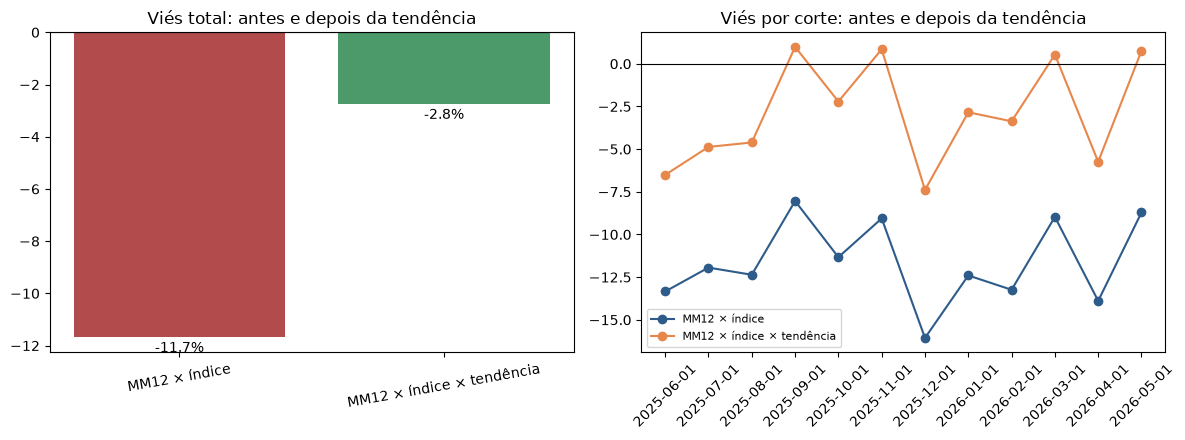

regua,MM12 × índice,MM12 × índice × tendência
cutoff,,
2025-06-01,-13.3,-6.5
2025-07-01,-11.9,-4.9
2025-08-01,-12.4,-4.6
2025-09-01,-8.0,1.0
2025-10-01,-11.3,-2.2
2025-11-01,-9.1,0.8
2025-12-01,-16.1,-7.4
2026-01-01,-12.4,-2.8
2026-02-01,-13.2,-3.4


In [8]:
# A mesma régua, sem e com o fator de tendência.
TENDENCIA = {"MM12 × índice": "pred_mm12_idx", "MM12 × índice × tendência": "pred_mm12_idx_trend"}
trend_effect = error_table(forecasts, TENDENCIA, reference="MM12 × índice")
display(trend_effect)

trend_by_cut = error_table(forecasts, TENDENCIA, by=["cutoff"], reference="MM12 × índice")
pivot_trend = trend_by_cut.pivot(index="cutoff", columns="regua", values="vies")[list(TENDENCIA)] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

bars = axes[0].bar(trend_effect["regua"], trend_effect["vies"] * 100, color=[CORES[3], CORES[2]])
axes[0].bar_label(bars, fmt="%.1f%%", padding=3)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Viés total: antes e depois da tendência")
axes[0].tick_params(axis="x", rotation=10)

for col, cor in zip(pivot_trend.columns, CORES):
    axes[1].plot(pivot_trend.index.astype(str), pivot_trend[col], marker="o", label=col, color=cor)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Viés por corte: antes e depois da tendência")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()
# Mesmos valores do gráfico, em tabela (viés %, por corte).
display(pivot_trend.round(1))


**O que o gráfico mostra:** **a correção de tendência reduz o viés total de −11,7% para −2,8%** e leva o viés de cada corte para a faixa de −7,4% a +1,0% (antes ficava entre −16% e −8%). Sem corrigir o crescimento, a previsão fica sistematicamente "atrasada" — como prever o preço da gasolina de hoje olhando só para o preço de alguns meses atrás, sem levar em conta que ele só sobe. **A tendência precisa ser feature**, porque médias do passado não têm como saber que a demanda está crescendo.

## 7. De onde vem o nível: da série, do produto ou da categoria?

As réguas acima usam a média **da própria série**. Como as séries são muito parecidas entre si, vale testar se a média de um grupo maior prevê melhor.

| Nível | Média mensal usada |
|---|---|
| Série | MM12 do próprio produto naquele local |
| Produto nos 6 locais | MM12 do mesmo produto, na média dos locais |
| Categoria no local | MM12 média dos produtos da categoria naquele local |

,regua,n,wape,vies,erro_relativo
0,série,72648,0.9310,-0.1168,1.0000
1,produto nos 6 locais,72648,0.8678,-0.1168,0.9322
2,categoria no local,72648,0.8563,-0.1168,0.9198


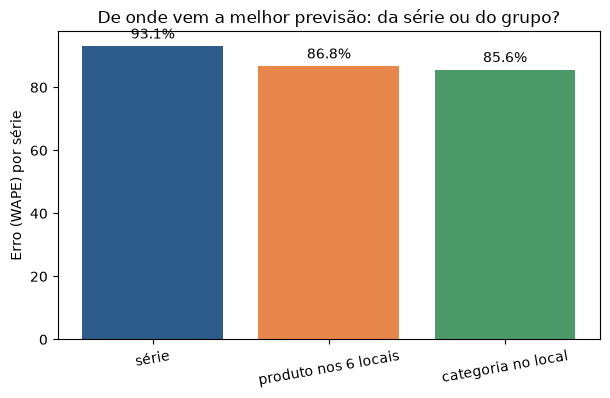

In [9]:
# De onde vem o nível: da série, do produto nos 6 locais ou da categoria no local.
NIVEIS = {
    "série": "pred_mm12_idx",
    "produto nos 6 locais": "pred_produto_idx",
    "categoria no local": "pred_categoria_loja_idx",
}
level_error = error_table(forecasts, NIVEIS, reference="série")
display(level_error)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(level_error["regua"], level_error["wape"] * 100, color=CORES[:3])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("Erro (WAPE) por série")
ax.set_title("De onde vem a melhor previsão: da série ou do grupo?")
plt.xticks(rotation=10)
plt.show()

**O que o gráfico mostra:** prever pela média do grupo erra **menos** do que usar o histórico da própria série, e prever pela categoria é tão bom quanto pelo mesmo produto nos outros locais. A série sozinha adiciona mais ruído que informação — apostar no comportamento do grupo funciona melhor do que tentar adivinhar o comportamento de cada produto sozinho.

## 8. Quem vendeu mais continua vendendo mais?

Em cada corte, as séries são divididas em 5 grupos iguais pela venda dos 12 meses anteriores (1 = as 20% que menos venderam; 5 = as 20% que mais venderam). Se produtos que vendem mais continuassem vendendo mais, a venda dos 3 meses seguintes subiria do grupo 1 para o grupo 5.

,quintil,series,venda_media_12m_antes,venda_media_3m_depois
0,1,14532,5.92,5.83
1,2,14532,13.76,5.74
2,3,14520,19.86,5.75
3,4,14532,26.71,5.62
4,5,14532,39.52,5.83


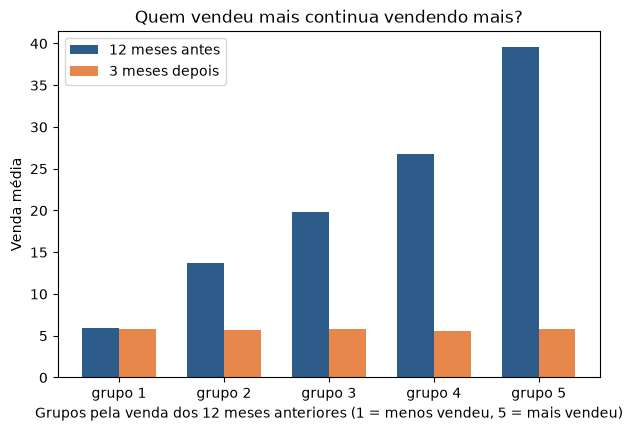

In [10]:
# Venda dos 12 meses antes x 3 meses depois, por quintil de venda passada.
quintiles = past_volume_quintiles(forecasts).reset_index()
display(quintiles)

fig, ax = plt.subplots(figsize=(7, 4.5))
x = range(len(quintiles))
width = 0.35
ax.bar([i - width / 2 for i in x], quintiles["venda_media_12m_antes"], width, color=CORES[0], label="12 meses antes")
ax.bar([i + width / 2 for i in x], quintiles["venda_media_3m_depois"], width, color=CORES[1], label="3 meses depois")
ax.set_xticks(list(x))
ax.set_xticklabels([f"grupo {q}" for q in quintiles["quintil"]])
ax.set_xlabel("Grupos pela venda dos 12 meses anteriores (1 = menos vendeu, 5 = mais vendeu)")
ax.set_ylabel("Venda média")
ax.set_title("Quem vendeu mais continua vendendo mais?")
ax.legend()
plt.show()

**O que o gráfico mostra:** as barras azuis (venda 12 meses antes) sobem bastante do grupo 1 para o grupo 5 — os grupos são bem diferentes na venda passada. Mas as barras laranjas (venda 3 meses depois) ficam praticamente **iguais** em todos os grupos. **Nenhuma série vende consistentemente mais que outra** — quem ficou entre os 20% que mais venderam num ano tem a mesma chance de repetir que qualquer outro. É como separar pessoas pelo resultado de uma jogada de dados: quem tirou os números mais altos numa rodada não tem mais chance de tirar números altos na próxima.

## 9. Erro quando as séries são somadas

A previsão de cada série erra muito por natureza: o ruído de venda é do tamanho da própria média (notebook 01). Mas quem usa a previsão normalmente soma séries, como na compra de uma categoria para uma loja ou no planejamento de um local.

regua,MM12,Categoria no local × índice × tendência (régua final)
nivel,,
série,99.2,86.6
produto\n(6 locais),49.8,34.8
categoria\n× local,36.4,11.9
local,35.5,6.1
total,35.3,3.3


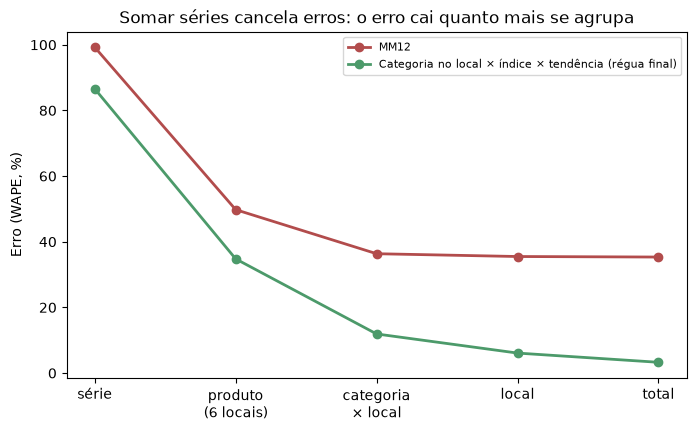

In [11]:
TODAS = {
    "MM12": "pred_mm12",
    "Categoria no local × índice × tendência (régua final)": "pred_categoria_loja_idx_trend",
}
# Níveis de soma, do mais detalhado ao total ([] = tudo somado).
levels = {
    "série": ["sk_product", "sk_location"],
    "produto\n(6 locais)": ["sk_product"],
    "categoria\n× local": ["category_name", "sk_location"],
    "local": ["sk_location"],
    "total": [],
}
# Erro calculado depois de somar previsão e venda real em cada nível.
aggregated = pd.concat(
    [aggregated_error_table(forecasts, TODAS, level).assign(nivel=name) for name, level in levels.items()]
)
pivot_agg = aggregated.pivot(index="nivel", columns="regua", values="wape")[list(TODAS)].loc[list(levels)] * 100
display(pivot_agg.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, cor in zip(pivot_agg.columns, [CORES[3], CORES[2]]):
    ax.plot(pivot_agg.index, pivot_agg[col], marker="o", label=col, color=cor, linewidth=2)
ax.set_ylabel("Erro (WAPE, %)")
ax.set_title("Somar séries cancela erros: o erro cai quanto mais se agrupa")
ax.legend(fontsize=8)
plt.show()

**O que o gráfico mostra:** pense numa pesquisa eleitoral — perguntar a 1 pessoa só dá um retrato impreciso; perguntar a milhares dá um retrato confiável, porque os erros individuais se cancelam. É o mesmo aqui: errar bastante ao prever a venda de *um* produto é esperado, mas ao somar dezenas de produtos numa categoria, ou centenas numa loja, os exageros para cima e para baixo se cancelam, e sobra um erro bem menor. A régua com tendência cai mais rápido que a MM12 pura — é a que sobra menos erro na soma, onde a previsão é usada de verdade.

## 10. A régua final

Junta o que as seções 6 a 9 mostraram: **média do grupo**, **índice sazonal** e **fator de tendência**. O gráfico compara os candidatos no nível em que a previsão é usada de verdade: somada por categoria no local.

**Fórmula:**

$$
\hat y_{i,c} = \frac{\bar s_{g(i),c}}{12} \times \text{season\_sum}_c \times \text{trend\_factor}(c)
$$

- $g(i)$ = grupo (categoria × loja) ao qual a série $i$ pertence
- $\bar s_{g(i),c}$ = nível do grupo no corte $c$ (seção 7)
- $\text{season\_sum}_c$ = soma dos índices sazonais dos 3 meses previstos a partir do corte $c$
- $\text{trend\_factor}(c)$ = fator de tendência do corte $c$ (seção 2)

,wape,vies,wape_categoria_x_local,wape_local
regua,,,,
MM12 × índice,0.9310,-0.1168,0.1507,0.1203
MM12 × índice × tendência,0.9554,-0.0275,0.1191,0.0609
categoria no local × índice,0.8563,-0.1168,0.1507,0.1203
categoria no local × índice × tendência,0.8657,-0.0275,0.1191,0.0609


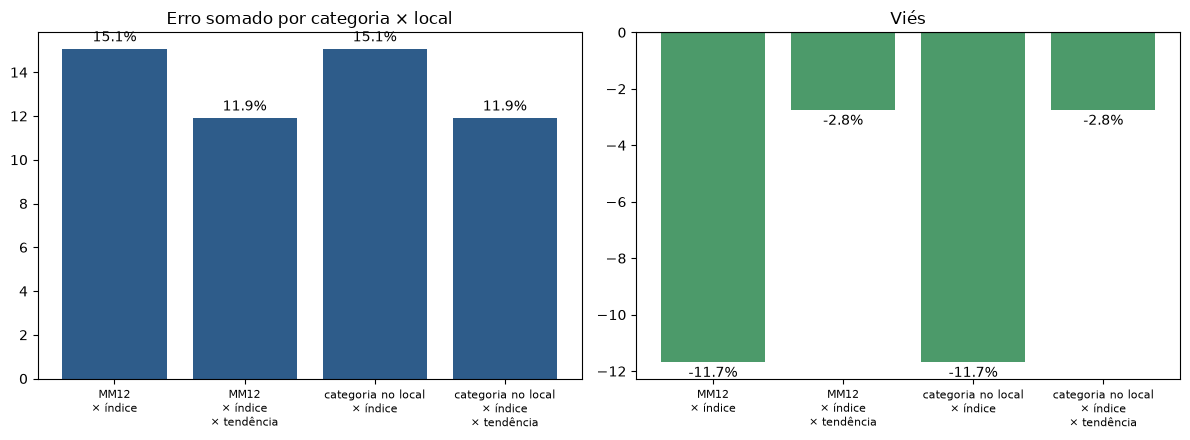

In [12]:
FINAIS = {
    "MM12 × índice": "pred_mm12_idx",
    "MM12 × índice × tendência": "pred_mm12_idx_trend",
    "categoria no local × índice": "pred_categoria_loja_idx",
    "categoria no local × índice × tendência": "pred_categoria_loja_idx_trend",
}
# Erro por série e viés de cada candidato.
final = error_table(forecasts, FINAIS, reference=None).set_index("regua")[["wape", "vies"]]
# Erro depois de somar por categoria no local e por local.
for name, level in {"categoria_x_local": ["category_name", "sk_location"], "local": ["sk_location"]}.items():
    final[f"wape_{name}"] = aggregated_error_table(forecasts, FINAIS, level).set_index("regua")["wape"]
display(final)

labels = [l.replace(" × ", "\n× ") for l in final.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars0 = axes[0].bar(labels, final["wape_categoria_x_local"] * 100, color=CORES[0])
axes[0].bar_label(bars0, fmt="%.1f%%", padding=3)
axes[0].set_title("Erro somado por categoria × local")
axes[0].tick_params(axis="x", labelsize=8)

colors_bias = [CORES[3] if v > 0 else CORES[2] for v in final["vies"]]
bars1 = axes[1].bar(labels, final["vies"] * 100, color=colors_bias)
axes[1].bar_label(bars1, fmt="%.1f%%", padding=3)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Viés")
axes[1].tick_params(axis="x", labelsize=8)

plt.tight_layout()
plt.show()

**O que o gráfico mostra:** a **categoria no local × índice × tendência** é a melhor régua. Ela empata com a MM12 × índice × tendência no erro somado (11,9% por categoria × local), porque somar por categoria × local dá o mesmo total nas duas contas; a diferença aparece por produto (86,6% contra 95,5%). Comparada às réguas sem tendência, ela tem menor erro somado (11,9% contra 15,1%) e viés bem mais perto de zero (−2,8% contra −11,7%). Esse conjunto (menor erro por produto, menor erro somado e viés perto de zero) é o que a torna uma base confiável para comparar com um modelo futuro.

**Por que não olhar só o erro por série:** com boa parte dos alvos em zero (38% nos 12 cortes de teste), o erro por série sozinho premia previsões abaixo da média (prever um pouco menos acerta mais zeros, mesmo errando o total). Por isso sempre olhamos o viés e o erro somado juntos, não só o erro por série.

## 11. A faixa de venda de cada produto

A previsão por produto entrega três números: a **quantidade esperada** (a régua final) e dois **limites de venda**. Os limites existem porque a venda de um produto sozinho varia muito em torno do esperado.

**Como a faixa é calculada, sem olhar o futuro:** em 24 cortes **anteriores** ao período de teste, as previsões são divididas em 10 grupos por tamanho; em cada grupo, guardamos até onde a venda real chegou em 75% e 90% das vezes (`q_75`, `q_90`). Nos 12 cortes de teste, cada previsão recebe os valores do grupo do seu tamanho.

**Fórmula:**

$$
q_{p,\,b} = \text{quantil}_p\big(\{\, y_i : \hat y_i \in \text{faixa } b \,\}\big)
$$

- $b$ = faixa (uma das 10, por tamanho da previsão $\hat y_i$) definida nos cortes de calibração
- $p \in \{0{,}25;\ 0{,}5;\ 0{,}75;\ 0{,}9\}$ = quantil pedido
- $q_{p,b}$ = valor da venda real que fica abaixo dele em $p$ dos casos daquela faixa, na calibração
- nos cortes de teste, cada previsão recebe os $q_{p,b}$ da faixa $b$ a que pertence

In [13]:
FINAL = "pred_categoria_loja_idx_trend"

# Calibra só com cortes anteriores ao teste, sem olhar o futuro.
calibration = forecasts_all[forecasts_all["cutoff"].isin(CALIBRATION_CUTOFFS)]
# Aprende q_75 e q_90 de cada faixa de tamanho da previsão.
buckets = fit_interval_buckets(calibration, FINAL)
# Cada previsão de teste recebe os limites da sua faixa.
forecasts = apply_interval_buckets(forecasts, buckets, FINAL)

buckets.round(2)

,bucket,lower,upper,n,q_25,q_50,q_75,q_90
0,0,1.50,2.06,14521,0.0,0.0,3.0,8.0
1,1,2.06,2.39,14513,0.0,0.0,3.0,8.0
2,2,2.39,3.12,14547,0.0,0.0,5.0,9.0
3,3,3.12,3.76,14535,0.0,0.0,6.0,10.0
4,4,3.76,4.45,14466,0.0,1.0,8.0,12.0
5,5,4.45,5.12,14578,0.0,3.0,9.0,13.0
6,6,5.12,5.66,14508,0.0,4.0,9.0,15.0
7,7,5.66,6.11,14543,0.0,5.0,10.0,16.0
8,8,6.11,6.66,14539,0.0,5.0,10.0,17.0
9,9,6.66,8.20,14540,0.0,6.0,11.0,17.0


**O que a tabela mostra:** com quantidade esperada baixa, mais da metade das vezes o produto não vende nada nos 3 meses (`q_50` = 0). Mesmo nas previsões maiores, a venda pode passar bastante do esperado em 1 de cada 10 vezes. Os limites transformam essa variação em números para decidir estoque.

## 12. Os limites acertam?

Se os limites estão bem calibrados, nos 12 cortes de teste a venda real deve ficar **até `q_75` em ~75%** e **até `q_90` em ~90%** das vezes.

,n,ate_q50,ate_q75,ate_q90
0,72648,0.516,0.752,0.898


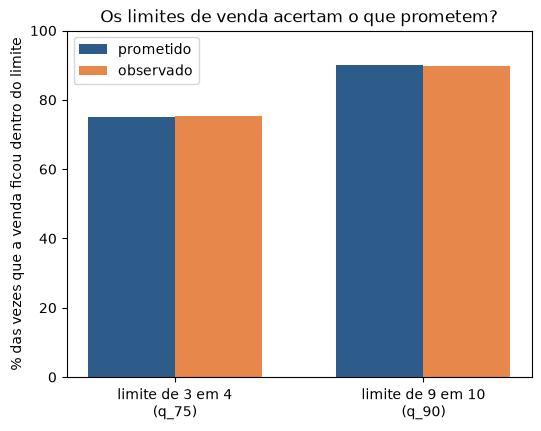

In [14]:
# % das vezes em que a venda real ficou até cada limite.
coverage = interval_coverage(forecasts)
display(coverage)

promised = {"q_75": 75, "q_90": 90}
observed = {"q_75": coverage["ate_q75"].iloc[0] * 100, "q_90": coverage["ate_q90"].iloc[0] * 100}

fig, ax = plt.subplots(figsize=(6, 4.5))
x = range(len(promised))
width = 0.35
ax.bar([i - width / 2 for i in x], list(promised.values()), width, color=CORES[0], label="prometido")
ax.bar([i + width / 2 for i in x], list(observed.values()), width, color=CORES[1], label="observado")
ax.set_xticks(list(x))
ax.set_xticklabels(["limite de 3 em 4\n(q_75)", "limite de 9 em 10\n(q_90)"])
ax.set_ylim(0, 100)
ax.set_ylabel("% das vezes que a venda ficou dentro do limite")
ax.set_title("Os limites de venda acertam o que prometem?")
ax.legend()
plt.show()

**O que o gráfico mostra:** o observado bate quase exatamente com o prometido — é o "teste de honestidade" dos tetos calculados na seção 11, feito em dados que a régua nunca tinha visto. **Os limites estão bem calibrados** e podem ser entregues com confiança para decidir estoque.

## 13. Como fica a entrega por produto

Um recorte real: motores da Loja Leão, previsão feita alguns meses atrás para os 3 meses seguintes, com o que de fato foi vendido depois. Cada barra é um **SKU** (uma variante do produto).

,sku,product_name,quantidade_esperada,q_75,q_90,vendido
109139,LHN-616875,Motor de Popa 6225,8.4,11.0,17.0,16.0
81923,LHN-018613,Motor de Popa 9201,8.4,11.0,17.0,9.0
124151,LHN-019188,Motor de Popa 4350,8.4,11.0,17.0,3.0
41318,LHN-019871,Motor de Popa 1606,8.4,11.0,17.0,10.0
121451,LHN-033536,Motor de Popa 1365,8.4,11.0,17.0,5.0
100643,LHN-037844,Motor de Popa 7678,8.4,11.0,17.0,5.0
30878,LHN-038883,Motor de Popa 8491,8.4,11.0,17.0,17.0
148631,LHN-049529,Motor de Popa 1007,8.4,11.0,17.0,17.0


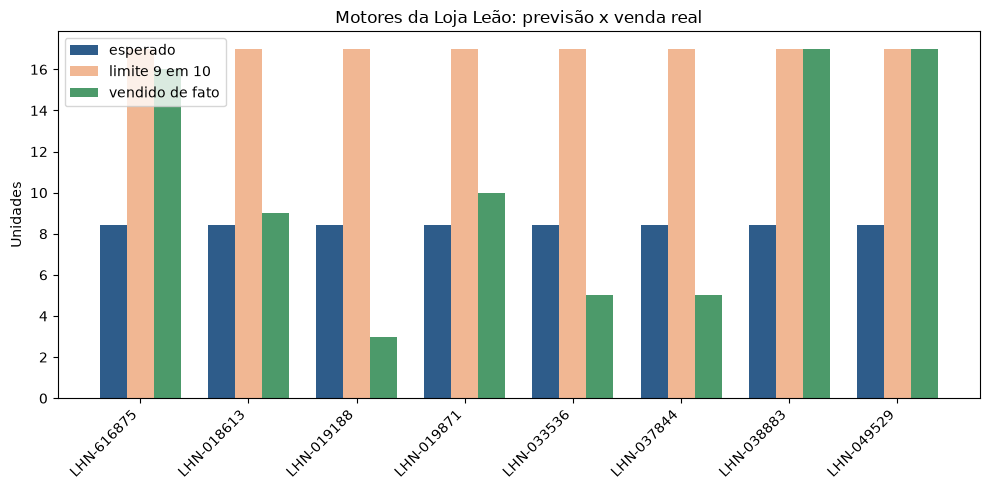

,n,ate_q50,ate_q75,ate_q90
0,112,0.455,0.723,0.866


In [15]:
# Corte de exemplo: 5 meses depois do primeiro corte de teste.
EXAMPLE_CUTOFF = add_months(CUTOFFS[0], 5)

# Recorte: motores da Loja Leão nesse corte.
delivery = forecasts[
    (forecasts["cutoff"] == EXAMPLE_CUTOFF)
    & (forecasts["location_name"] == "Loja Leão")
    & (forecasts["category_name"] == "Motores")
].sort_values("sku")

# Um SKU em destaque mais 7 outros, para o gráfico.
example = delivery["sku"] == "LHN-616875"
sample = pd.concat([delivery[example], delivery[~example].head(7)])
display(
    sample[["sku", "product_name", FINAL, "q_75", "q_90", "target_3m"]].rename(
        columns={FINAL: "quantidade_esperada", "target_3m": "vendido"}
    ).round(1)
)

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(sample))
width = 0.25
ax.bar([i - width for i in x], sample[FINAL], width, color=CORES[0], label="esperado")
ax.bar([i for i in x], sample["q_90"], width, color=CORES[1], alpha=0.6, label="limite 9 em 10")
ax.bar([i + width for i in x], sample["target_3m"], width, color=CORES[2], label="vendido de fato")
ax.set_xticks(list(x))
ax.set_xticklabels(sample["sku"], rotation=45, ha="right")
ax.set_ylabel("Unidades")
ax.set_title("Motores da Loja Leão: previsão x venda real")
ax.legend()
plt.tight_layout()
plt.show()

# Nos motores dessa loja e corte, quantos ficaram dentro de cada limite.
interval_coverage(delivery)

**O que o gráfico mostra:** todos os motores da loja recebem a mesma quantidade esperada e os mesmos limites — só o que muda é o quanto cada um de fato vendeu depois. Na maioria, a venda real fica perto do esperado ou dentro do limite de 9 em 10; ocasionalmente um SKU passa um pouco do limite, o que é esperado (o limite promete acertar 9 em cada 10 vezes, não 10 em 10).

**Observação sobre os dados:** o nome do produto pode se repetir entre SKUs diferentes (variantes do mesmo modelo). As séries são identificadas pelo SKU, então isso não afeta a previsão.

## 14. A base de comparação

O quadro abaixo é a **referência para comparar qualquer previsão nova**, como um modelo de machine learning feito na próxima etapa. Cada métrica tem um nome que diz o que é e em que nível é medida.

| Métrica | Nível | O que mede | Melhor |
|---|---|---|---|
| `wape_produto` | produto × local | Erro (WAPE): de cada 100 unidades vendidas, quantas a previsão errou | Menor, mas lembre da armadilha: premia prever abaixo |
| `mae_produto` | produto × local | Erro médio absoluto, em unidades (MAE) | Menor |
| `rmse_produto` | produto × local | Raiz do erro quadrático médio, em unidades (RMSE) — pesa mais os erros grandes que o MAE | Menor |
| `wape_categoria_local` | soma por categoria no local | Erro (WAPE) depois de somar os produtos | Menor |
| `wape_local` | soma por local | Erro (WAPE) depois de somar os produtos | Menor |
| `vies` | total | Se erra sempre para o mesmo lado | Perto de zero |

A régua só é considerada boa se for boa em **todas** essas visões ao mesmo tempo, não só na mais fácil de manipular. Fórmulas de WAPE e viés: seção 3.

$$
\text{MAE} = \frac{1}{n}\sum_i |\hat y_i - y_i|
\qquad
\text{RMSE} = \sqrt{\frac{1}{n}\sum_i (\hat y_i - y_i)^2}
$$

- $y_i$/$\hat y_i$ = real/previsto da série $i$ (mesma notação da seção 3)
- MAE e RMSE são medidos em **unidades vendidas**, por produto × local, não em %; por isso não dá para comparar seu valor diretamente entre produtos de tamanhos muito diferentes — use junto com o WAPE para isso
- Por categoria no local e por local usamos o **WAPE**, que é uma proporção e compara bem grupos de tamanhos diferentes
- RMSE ≥ MAE sempre; quanto maior a diferença entre os dois, mais a régua está errando feio em algumas séries específicas (em vez de errar um pouco em todas)

,wape_produto,mae_produto,rmse_produto,wape_categoria_local,wape_local,vies
previsao,,,,,,
MM3,1.2047,6.93,9.46,0.4958,0.4872,-0.0193
MM12,0.9923,5.71,7.40,0.3635,0.3550,-0.0808
MM12 × índice,0.9310,5.36,7.13,0.1507,0.1203,-0.1168
Régua final: categoria no local × índice × tendência,0.8657,4.98,6.38,0.1191,0.0609,-0.0275


,nível,métrica,régua final
0,produto × loja,WAPE,0.8657
1,produto × loja,MAE (unidades),4.9800
2,produto × loja,RMSE (unidades),6.3800
3,categoria no local,WAPE,0.1191
4,local,WAPE,0.0609
5,total,viés,-0.0275


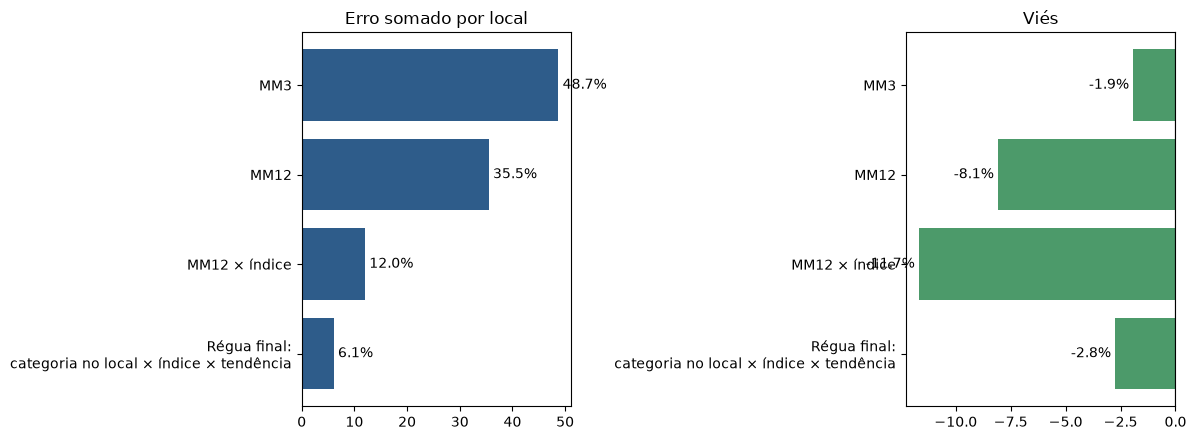

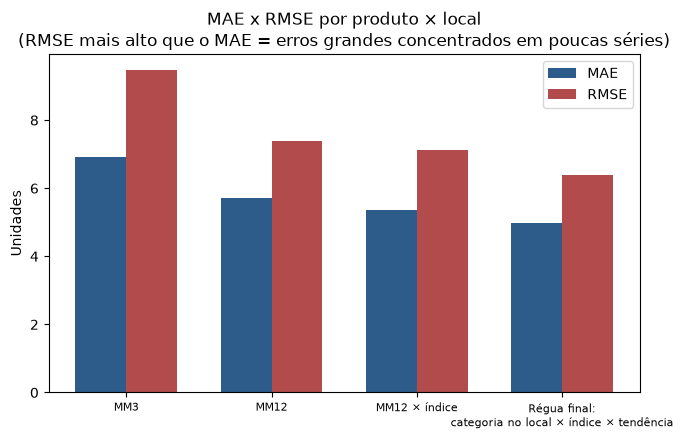

In [16]:
BASE = {
    "MM3": "pred_mm3",
    "MM12": "pred_mm12",
    "MM12 × índice": "pred_mm12_idx",
    "Régua final: categoria no local × índice × tendência": FINAL,
}
# comparison_scorecard também calcula o desvio de Poisson (métrica avançada,
# fora do escopo deste resumo); WAPE, MAE, RMSE por produto e viés ficam todos na tabela.
scorecard = comparison_scorecard(forecasts, BASE).drop(columns=["desvio_poisson"])
display(scorecard)

# A "nota a superar": a linha da régua final, métrica por métrica.
REGUA_FINAL = "Régua final: categoria no local × índice × tendência"
nota = scorecard.loc[REGUA_FINAL]
nota_a_superar = pd.DataFrame(
    {
        "nível": ["produto × loja", "produto × loja", "produto × loja", "categoria no local", "local", "total"],
        "métrica": ["WAPE", "MAE (unidades)", "RMSE (unidades)", "WAPE", "WAPE", "viés"],
        "régua final": [
            nota["wape_produto"],
            nota["mae_produto"],
            nota["rmse_produto"],
            nota["wape_categoria_local"],
            nota["wape_local"],
            nota["vies"],
        ],
    }
)
display(nota_a_superar)

labels = [l.replace(": ", ":\n") for l in scorecard.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bars0 = axes[0].barh(labels, scorecard["wape_local"] * 100, color=CORES[0])
axes[0].bar_label(bars0, fmt="%.1f%%", padding=3)
axes[0].set_title("Erro somado por local")
axes[0].invert_yaxis()

colors_bias = [CORES[3] if v > 0 else CORES[2] for v in scorecard["vies"]]
bars1 = axes[1].barh(labels, scorecard["vies"] * 100, color=colors_bias)
axes[1].bar_label(bars1, fmt="%.1f%%", padding=3)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Viés")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
width = 0.35
x = range(len(scorecard))
ax.bar([i - width / 2 for i in x], scorecard["mae_produto"], width, color=CORES[0], label="MAE")
ax.bar([i + width / 2 for i in x], scorecard["rmse_produto"], width, color=CORES[3], label="RMSE")
ax.set_xticks(list(x))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Unidades")
ax.set_title("MAE x RMSE por produto × local\n(RMSE mais alto que o MAE = erros grandes concentrados em poucas séries)")
ax.legend()
plt.tight_layout()
plt.show()

**O que o gráfico mostra:** a régua final tem o menor erro em todas as visões (86,6% por produto, 11,9% por categoria no local e 6,1% por local) e viés de −2,8%. Só a MM3 tem viés menor (−1,9%), mas erra 49,6% por categoria no local, então viés perto de zero sozinho não basta. **Estes são os números a superar** com um modelo de machine learning mais sofisticado: o quadro "nota a superar" reúne, em uma tabela só, o WAPE, o MAE e o RMSE por produto × loja, o WAPE por categoria no local e por local, e o viés.

### Como comparar a sua previsão com a base

1. Gere a sua previsão com uma linha por `cutoff`, `sk_product` e `sk_location`, para os mesmos 12 cortes de teste (`CUTOFFS`), e o total previsto dos 3 meses seguintes numa coluna, por exemplo `pred_modelo`.
2. Junte ao painel e rode o mesmo quadro:

```python
comparacao = forecasts.merge(minha_previsao, on=["cutoff", "sk_product", "sk_location"], how="left")
comparison_scorecard(comparacao, {"régua": FINAL, "meu modelo": "pred_modelo"})
```

Isso já devolve, na mesma tabela, WAPE, MAE e RMSE por produto × loja (`wape_produto`, `mae_produto`, `rmse_produto`), WAPE por categoria no local e por local (`wape_categoria_local`, `wape_local`) e o `vies`.

3. Se entregar limites, nomeie-os `q_50`, `q_75` e `q_90` e use `interval_coverage`.

**Regra para dizer que é melhor:** menor WAPE por categoria no local e por local, viés mais perto de zero, e WAPE, MAE e RMSE por produto menores, na maioria dos 12 cortes — e não só na média.

## Conclusão

**Em uma frase, para quem não trabalha com dados:** para prever quanto um produto vai vender numa loja, funciona melhor olhar para o comportamento do grupo dele (categoria + loja), ajustado pela época do ano e pelo crescimento das vendas, do que tentar adivinhar pelo histórico daquele produto específico — porque o histórico individual de cada produto é, na prática, resultado de sorte, não de um padrão que se repete.

### A base de comparação

**Régua final: categoria no local × índice sazonal × tendência**, com limites de venda por produto. Qualquer previsão nova é comparada nos mesmos 12 cortes e com a mesma função (seção 14):

| Medida | Nível | Régua final | Uma previsão melhor precisa |
|---|---|---|---|
| WAPE | produto × loja | 86,6% | ficar abaixo |
| MAE (unidades) | produto × loja | 4,98 | ficar abaixo |
| RMSE (unidades) | produto × loja | 6,38 | ficar abaixo |
| WAPE | categoria × local | 11,9% | ficar abaixo |
| WAPE | local | 6,1% | ficar abaixo |
| Viés | total | −2,8% | ficar mais perto de zero |
| Limites (q_75 / q_90) | produto × loja | ~75% / ~90% | manter ~75% / ~90% |

A melhora precisa aparecer na maioria dos 12 cortes, e não só na média.

**Como avaliar:** por **todas** as métricas da tabela ao mesmo tempo. O erro por produto (WAPE, MAE, RMSE) mostra quanto se erra em cada série; o erro somado e o viés mostram se a previsão serve para decidir compra por categoria e por loja. O WAPE por produto sozinho premia prever abaixo do real.

### O que isso muda na engenharia de features

| Grupo de features | Veredito | Por quê |
|---|---|---|
| **Nível do grupo** (média por série da categoria no local; média geral por série) | **Essencial** | Prevê melhor que a própria série (seção 7) |
| **Índice sazonal** dos 3 meses previstos | **Essencial** | Remove o viés de época (seção 5) |
| **Tendência** (crescimento de 12 meses no corte; fator de tendência) | **Essencial** | Remove o viés e corta o erro somado (seções 6 e 9) |
| Histórico da própria série (MM3, MM12, meses com venda) | **Provavelmente inútil** | O volume de uma série não se repete de um ano para o outro (seção 8); só testar para confirmar |
| Produto nos outros locais | **Provavelmente inútil** | O produto também não se repete entre anos, e empata com a categoria (seção 7) |
| Atributos (categoria, local, preço) | Baixa prioridade | Todas as categorias e locais vendem parecido por série |

**Expectativa honesta:** esta régua já captura quase tudo o que os dados permitem prever. Um modelo pode ganhar ajustando sazonalidade e tendência com mais precisão por grupo, mas o ganho deve ser pequeno. Se não superar a régua, a régua é a previsão recomendada.